In [1]:
!pip install -q transformers sentencepiece indic-nlp-library matplotlib pandas

In [2]:
from transformers import AutoTokenizer
import pandas as pd
import matplotlib.pyplot as plt

text = "నేను తెలుగు నేర్చుకుంటున్నాను"
print(text)
print("Characters:", len(text))
print("Words:", len(text.split()))

నేను తెలుగు నేర్చుకుంటున్నాను
Characters: 29
Words: 3


In [3]:
tok = AutoTokenizer.from_pretrained("xlm-roberta-base")

tokens = tok.tokenize(text)
print(tokens)
print("Token count:", len(tokens))
print("Tokens per word:", len(tokens) / len(text.split()))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

['▁నేను', '▁తెలుగు', '▁నేర్చ', 'ుకుంటున్న', 'ాను']
Token count: 5
Tokens per word: 1.6666666666666667


In [4]:
model_names = {
    "mBERT": "bert-base-multilingual-cased",
    "XLM-R": "xlm-roberta-base",
    "MuRIL": "google/muril-base-cased",
    "IndicBERT": "ai4bharat/IndicBERTv2-MLM-only",
    "GPT-2": "gpt2",
}

tokenizers = {}
for name, path in model_names.items():
    try:
        tokenizers[name] = AutoTokenizer.from_pretrained(path)
        print("loaded:", name)
    except Exception as e:
        print("FAILED:", name, "->", str(e)[:100])

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

loaded: mBERT
loaded: XLM-R


...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

loaded: GPT-2


In [5]:
words = text.split()

for name, t in tokenizers.items():
    toks = t.tokenize(text)
    print(f"\n{name}")
    print(toks)
    print("tokens:", len(toks), "| fertility:", round(len(toks) / len(words), 2))



mBERT
['న', '##ే', '##ను', 'తెలుగు', 'న', '##ే', '##ర్', '##చు', '##కు', '##ం', '##టు', '##న్న', '##ాను']
tokens: 13 | fertility: 4.33

XLM-R
['▁నేను', '▁తెలుగు', '▁నేర్చ', 'ుకుంటున్న', 'ాను']
tokens: 5 | fertility: 1.67

MuRIL
['నేను', 'తెలుగు', 'నే', '##ర్', '##చు', '##కుంట', '##ున్నా', '##ను']
tokens: 8 | fertility: 2.67

IndicBERT
['నేను', 'తెలుగు', 'నేర్చు', '##కుంటున్నా', '##ను']
tokens: 5 | fertility: 1.67

GPT-2
['à', '°', '¨', 'à', '±', 'ĩ', 'à', '°', '¨', 'à', '±', 'ģ', 'Ġ', 'à', '°', '¤', 'à', '±', 'Ĩ', 'à', '°', '²', 'à', '±', 'ģ', 'à', '°', 'Ĺ', 'à', '±', 'ģ', 'Ġ', 'à', '°', '¨', 'à', '±', 'ĩ', 'à', '°', '°', 'à', '±', 'į', 'à', '°', 'ļ', 'à', '±', 'ģ', 'à', '°', 'ķ', 'à', '±', 'ģ', 'à', '°', 'Ĥ', 'à', '°', 'Ł', 'à', '±', 'ģ', 'à', '°', '¨', 'à', '±', 'į', 'à', '°', '¨', 'à', '°', '¾', 'à', '°', '¨', 'à', '±', 'ģ']
tokens: 83 | fertility: 27.67


In [6]:
sentences = [
    "నేను తెలుగు నేర్చుకుంటున్నాను",
    "ఈ రోజు వాతావరణం చాలా బాగుంది",
    "మా అమ్మ నాకు రుచికరమైన భోజనం వండి పెట్టింది",
    "విద్యార్థులు పరీక్షల కోసం కష్టపడి చదువుతున్నారు",
    "హైదరాబాదులో ఉన్న స్నేహితులను కలుసుకోవడానికి వెళ్తున్నాను",
]

rows = []
for s in sentences:
    n_words = len(s.split())
    for name, t in tokenizers.items():
        n_tokens = len(t.tokenize(s))
        rows.append({
            "sentence": s,
            "tokenizer": name,
            "words": n_words,
            "tokens": n_tokens,
            "fertility": n_tokens / n_words,
        })

df = pd.DataFrame(rows)
summary = df.groupby("tokenizer")["fertility"].mean().sort_values()
print(summary.round(2))

tokenizer
IndicBERT     1.39
XLM-R         1.89
MuRIL         2.03
mBERT         3.94
GPT-2        23.64
Name: fertility, dtype: float64


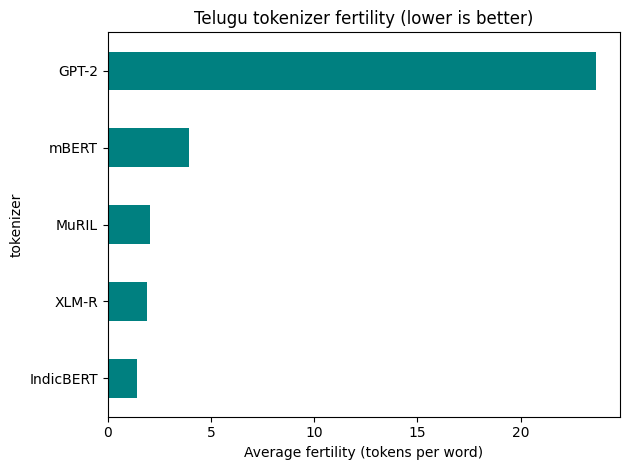

In [7]:
summary.plot(kind="barh", color="teal")
plt.xlabel("Average fertility (tokens per word)")
plt.title("Telugu tokenizer fertility (lower is better)")
plt.tight_layout()
plt.show()

In [8]:
hard_words = ["నేర్చుకుంటున్నాను", "కలుసుకోవడానికి", "హైదరాబాదులో"]

for w in hard_words:
    print("\n" + "=" * 50)
    print(w, "| characters:", len(w))
    for name, t in tokenizers.items():
        toks = t.tokenize(w)
        print(f"{name:10} {len(toks):3} tokens  {toks}")


నేర్చుకుంటున్నాను | characters: 17
mBERT        9 tokens  ['న', '##ే', '##ర్', '##చు', '##కు', '##ం', '##టు', '##న్న', '##ాను']
XLM-R        3 tokens  ['▁నేర్చ', 'ుకుంటున్న', 'ాను']
MuRIL        6 tokens  ['నే', '##ర్', '##చు', '##కుంట', '##ున్నా', '##ను']
IndicBERT    3 tokens  ['నేర్చు', '##కుంటున్నా', '##ను']
GPT-2       51 tokens  ['à', '°', '¨', 'à', '±', 'ĩ', 'à', '°', '°', 'à', '±', 'į', 'à', '°', 'ļ', 'à', '±', 'ģ', 'à', '°', 'ķ', 'à', '±', 'ģ', 'à', '°', 'Ĥ', 'à', '°', 'Ł', 'à', '±', 'ģ', 'à', '°', '¨', 'à', '±', 'į', 'à', '°', '¨', 'à', '°', '¾', 'à', '°', '¨', 'à', '±', 'ģ']

కలుసుకోవడానికి | characters: 14
mBERT        7 tokens  ['క', '##లు', '##సు', '##క', '##ో', '##వ', '##డానికి']
XLM-R        4 tokens  ['▁', 'కలు', 'స', 'ుకోవడానికి']
MuRIL        4 tokens  ['కల', '##ు', '##సు', '##కోవడానికి']
IndicBERT    3 tokens  ['కలు', '##సుకో', '##వడానికి']
GPT-2       42 tokens  ['à', '°', 'ķ', 'à', '°', '²', 'à', '±', 'ģ', 'à', '°', '¸', 'à', '±', 'ģ', 'à', '°', 'ķ', 'à', '±', 'ĭ

In [9]:
w = "నేర్చుకుంటున్నాను"
print("characters:", len(w))
print("UTF-8 bytes:", len(w.encode("utf-8")))
print("GPT-2 tokens:", len(tokenizers["GPT-2"].tokenize(w)))

characters: 17
UTF-8 bytes: 51
GPT-2 tokens: 51
